In [24]:
# Project-Student Performance Predictor
# Name-Abdur Rehman
# Roll No-22F-BSCS-171

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score,
                             precision_score, recall_score, confusion_matrix)

# Student Performance Predictor
Dataset: UCI Student Performance (student-mat.csv), 395 students, 33 columns.
Study hours = studytime, attendance = absences, assignment scores = G1, G2.

Preprocessing: fill missing values, pass/fail column (G3 >= 10 is pass), text to numbers, train/test split, scaling.

Models: Linear Regression (marks), Logistic Regression and Decision Tree (pass/fail), compared using accuracy, precision and recall.

In [25]:
# here i will load the dataset
df = pd.read_csv("student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [26]:
# next step here i will preprocess the data



print("Missing values:", df.isnull().sum().sum())
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# G3 is 10 or more than 10 so it will be pass (1) and if 0 means fail
df["pass"] = (df["G3"] >= 10).astype(int)


df_num = pd.get_dummies(df, drop_first=True)

X = df_num.drop(columns=["G3", "pass"])
y_marks = df_num["G3"]
y_pass = df_num["pass"]

X_train, X_test, marks_train, marks_test, pass_train, pass_test = train_test_split(
    X, y_marks, y_pass, test_size=0.2, random_state=42, stratify=y_pass)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Missing values: 0


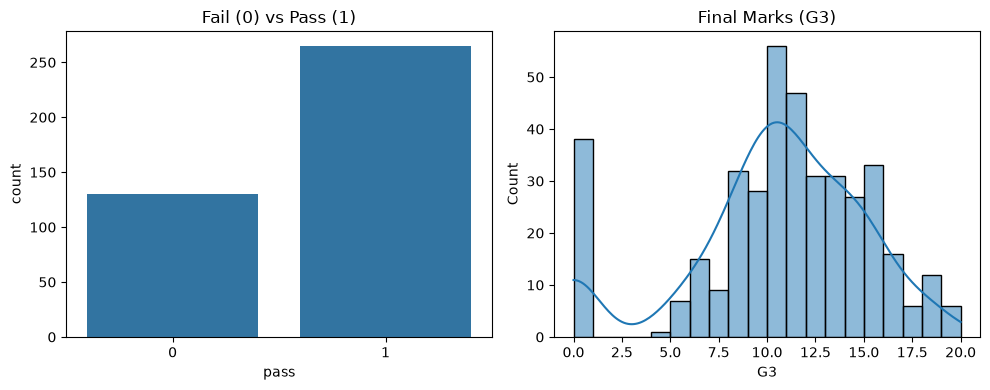

In [27]:
# here i will try to visualize the data 

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="pass", data=df, ax=ax[0])
ax[0].set_title("Fail (0) vs Pass (1)")
sns.histplot(df["G3"], bins=20, kde=True, ax=ax[1])
ax[1].set_title("Final Marks (G3)")
plt.tight_layout()
plt.show()

In [28]:
# this is Model 1 Linear Regression 

lin_model = LinearRegression()
lin_model.fit(X_train, marks_train)
predicted_marks = lin_model.predict(X_test)

print("MAE:", round(mean_absolute_error(marks_test, predicted_marks), 3))
print("R2 :", round(r2_score(marks_test, predicted_marks), 3))

MAE: 1.544
R2 : 0.771


In [29]:
# here model 2 and 3 which is Logistic Regression and Decision Tree 


log_model = LogisticRegression(max_iter=1000)
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)

log_model.fit(X_train, pass_train)
tree_model.fit(X_train, pass_train)

log_pred = log_model.predict(X_test)
tree_pred = tree_model.predict(X_test)



results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(pass_test, log_pred), accuracy_score(pass_test, tree_pred)],
    "Precision": [precision_score(pass_test, log_pred), precision_score(pass_test, tree_pred)],
    "Recall": [recall_score(pass_test, log_pred), recall_score(pass_test, tree_pred)],
}).round(3)
results

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.848,0.936,0.83
1,Decision Tree,0.873,0.978,0.83


In [30]:
# the models i used here i will find confusion matrix 


log_model = LogisticRegression(max_iter=1000)
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)

log_model.fit(X_train, pass_train)
tree_model.fit(X_train, pass_train)

log_pred = log_model.predict(X_test)
tree_pred = tree_model.predict(X_test)


results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy_score(pass_test, log_pred), accuracy_score(pass_test, tree_pred)],
    "Precision": [precision_score(pass_test, log_pred), precision_score(pass_test, tree_pred)],
    "Recall": [recall_score(pass_test, log_pred), recall_score(pass_test, tree_pred)],
}).round(3)
results

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.848,0.936,0.83
1,Decision Tree,0.873,0.978,0.83


## Conclusion
- Linear Regression: R2 = 0.771, MAE = 1.54 marks. The model predicts final marks well.
- Logistic Regression accuracy = 0.848, Decision Tree accuracy = 0.873. Better model: Decision Tree.